<div style="background:#1F3A5F; color:#F4F6F8; padding:54px 48px 44px 48px; border-radius:10px; margin:6px 0 22px 0; font-family:Georgia,'Times New Roman',serif;">
<div style="font-size:0.82em; letter-spacing:0.24em; text-transform:uppercase; color:#9CC9D1;">Probabilidad y Estadística · Capítulo 4</div>
<h1 style="color:#FFFFFF; font-size:2.5em; font-weight:600; line-height:1.15; margin:20px 0 14px 0; border:none; padding:0;">Taller de distribuciones de probabilidad</h1>
<p style="font-size:1.3em; margin:0 0 4px 0; color:#FFFFFF;"><strong>Presentado por: Santiago Suárez Claros</strong></p>
<p style="font-size:1.05em; margin:0 0 26px 0; color:#D5DEE8;">Código estudiantil: 2453853</p>
<hr style="border:0; border-top:2px solid #2A7F8E; width:90px; margin:0 0 20px 0;">
<p style="font-size:1.02em; line-height:1.55; margin:0; color:#D5DEE8;">Quince ejercicios con desarrollo analítico paso a paso y verificación computacional en Julia.</p>
</div>

| | |
|:--|:--|
| **Asignatura** | Probabilidad y Estadística |
| **Capítulo** | 4. Distribuciones de probabilidad |
| **Texto base** | *Schaum's Outline of Probability and Statistics*, 4.ª ed., problemas suplementarios |
| **Estudiante** | Santiago Suárez Claros |
| **Código estudiantil** | 2453853 |
| **Entorno** | Julia 1.12 con IJulia |

<a id="sec-indice"></a>

# Tabla de contenido

| Sección | Contenido |
|:--|:--|
| [1. Introducción](#sec-intro) | Propósito del trabajo, convenciones y fórmulas de referencia |
| [2. Preparación del entorno](#sec-entorno) | Paquetes, paleta gráfica y funciones auxiliares |
| [3. Selección de los ejercicios](#sec-seleccion) | Sorteo con el código estudiantil y verificación de la lista |
| [4. Desarrollo de los ejercicios](#sec-desarrollo) | Los quince ejercicios asignados |
| [5. Resumen de resultados](#sec-resumen) | Tabla consolidada de respuestas |
| [6. Observaciones sobre la fuente](#sec-observaciones) | Inconsistencias detectadas y su tratamiento |
| [7. Referencias bibliográficas](#sec-referencias) | Texto base y documentación del software |

### Ejercicios asignados

| Ejercicio | Tema | Herramienta principal | Figura |
|:--|:--|:--|:--:|
| [4.66](#ej-4-66) | Exactamente un éxito en tres lanzamientos | Distribución binomial | |
| [4.67](#ej-4-67) | Examen de verdadero o falso adivinado | Distribución binomial | 1 |
| [4.72](#ej-4-72) | Puntuaciones estándar y calificaciones | Estandarización | |
| [4.73](#ej-4-73) | Media y desviación estándar a partir de puntuaciones | Sistema lineal | |
| [4.75](#ej-4-75) | Áreas bajo la curva normal estándar | Normal estándar | 2 |
| [4.79](#ej-4-79) | Probabilidad de una variable normal | Distribución normal | 3 |
| [4.83](#ej-4-83) | Distancias respecto a la media | Normal estándar | |
| [4.84](#ej-4-84) | Porcentajes en intervalos de la normal | Normal estándar | |
| [4.88](#ej-4-88) | Pernos defectuosos | Aproximación normal a la binomial | 4 |
| [4.90](#ej-4-90) | Bombillas defectuosas | Distribución de Poisson | 5 |
| [4.99](#ej-4-99) | Selección de cartas sin reemplazo | Distribución hipergeométrica | |
| [4.100](#ej-4-100) | Aspirantes seleccionados al azar | Distribución hipergeométrica | 6 |
| [4.102](#ej-4-102) | Momentos centrales de la uniforme | Cálculo integral | |
| [4.116](#ej-4-116) | Cuantiles con 15 grados de libertad | Distribución t de Student | |
| [4.117](#ej-4-117) | Valores críticos según los grados de libertad | Distribución t de Student | 7 |

<a id="sec-intro"></a>

# 1. Introducción

Este cuaderno desarrolla los quince ejercicios del capítulo 4 asignados mediante el sorteo del código estudiantil **2453853**. Cada problema se resuelve primero de forma analítica y luego se verifica con Julia, de modo que el procedimiento escrito y el cálculo numérico se respaldan mutuamente.

### Estructura de cada ejercicio

| Apartado | Función |
|:--|:--|
| Encabezado | Número del ejercicio y tema |
| Enunciado | Traducción del problema, en un recuadro azul |
| Datos y conceptos | Parámetros conocidos y resultados teóricos que se emplean |
| Desarrollo matemático | Procedimiento paso a paso |
| Implementación computacional | Descripción del código y celda de Julia |
| Resultados e interpretación | Respuesta final, en un recuadro verde, y su lectura en contexto |

Las observaciones sobre inconsistencias del texto base se destacan en recuadros ocres.

### Convenciones

- Los decimales se escriben con punto.
- $\Phi(z)=P(Z\leq z)$ denota la función de distribución acumulada de $Z\sim N(0,1)$.
- $\mathrm{Bin}(n,p)$, $\mathrm{Poisson}(\lambda)$, $N(\mu,\sigma^2)$ y $t_\nu$ designan las distribuciones binomial, de Poisson, normal y t de Student.
- Las figuras y las tablas de resultados numéricos se generan al ejecutar las celdas de código.

<details>
<summary><strong>Fórmulas de referencia utilizadas en el taller</strong></summary>

| Distribución | Función de masa o de densidad | Media | Varianza |
|:--|:--|:--:|:--:|
| Binomial $\mathrm{Bin}(n,p)$ | $\displaystyle P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ |
| Poisson $\mathrm{Poisson}(\lambda)$ | $\displaystyle P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!}$ | $\lambda$ | $\lambda$ |
| Hipergeométrica | $\displaystyle P(X=k)=\frac{\binom{K}{k}\binom{N-K}{n-k}}{\binom{N}{n}}$ | $n\dfrac{K}{N}$ | $n\dfrac{K}{N}\left(1-\dfrac{K}{N}\right)\dfrac{N-n}{N-1}$ |
| Normal $N(\mu,\sigma^2)$ | $\displaystyle f(x)=\frac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/(2\sigma^2)}$ | $\mu$ | $\sigma^2$ |
| Uniforme $U(a,b)$ | $\displaystyle f(x)=\frac{1}{b-a},\ a\leq x\leq b$ | $\dfrac{a+b}{2}$ | $\dfrac{(b-a)^2}{12}$ |

Estandarización: $\displaystyle z=\frac{x-\mu}{\sigma}$. Aproximación normal a la binomial: $\mu=np$ y $\sigma=\sqrt{npq}$, con corrección de continuidad de media unidad.

</details>

<a id="sec-entorno"></a>

# 2. Preparación del entorno

Se emplean tres paquetes externos: `Distributions.jl` para las distribuciones y sus funciones de probabilidad, `StatsBase.jl` para el muestreo sin reemplazo del sorteo y `Plots.jl` para las gráficas. La primera celda instala únicamente los paquetes que aún no estén disponibles, por lo que se ejecuta una sola vez por entorno.

In [68]:
import Pkg

for paquete in ["Distributions", "StatsBase", "Plots"]
    if Base.find_package(paquete) === nothing
        Pkg.add(paquete)
    end
end

La siguiente celda carga los paquetes y fija la identidad gráfica del cuaderno: una paleta sobria de cinco colores (azul marino, verde azulado, ocre, rojo ladrillo y gris) y un estilo común para todas las figuras. También define tres funciones auxiliares:

| Función | Propósito |
|:--|:--|
| `cifra(valor, formato)` | Convierte un número en texto con el formato indicado, por ejemplo `"%.4f"` |
| `mostrar_tabla(encabezados, filas)` | Presenta una tabla HTML con el mismo diseño de las tablas de Markdown |
| `grafica_region_normal(distribucion, condicion; ...)` | Dibuja una densidad normal y sombrea la región que cumple la condición |

In [69]:
using Random
using Printf
using StatsBase
using Distributions
using Plots

const PALETA = (
    primario = "#1F3A5F",
    secundario = "#2A7F8E",
    acento = "#C08A2B",
    alerta = "#A63D40",
    neutro = "#6B7785",
)

default(
    size = (900, 480),
    framestyle = :box,
    linewidth = 2.5,
    grid = true,
    gridalpha = 0.25,
    titlefontsize = 13,
    guidefontsize = 11,
    tickfontsize = 9,
    legendfontsize = 9,
    legend = :topright,
    foreground_color_legend = nothing,
    margin = 5Plots.mm,
    palette = [PALETA.primario, PALETA.secundario, PALETA.acento, PALETA.alerta, PALETA.neutro],
)

function cifra(valor, formato = "%.6f")
    return Printf.format(Printf.Format(formato), valor)
end

function escapar_html(texto)
    return replace(string(texto), "&" => "&amp;", "<" => "&lt;", ">" => "&gt;")
end

function mostrar_tabla(encabezados, filas)
    estilo_tabla = "border-collapse:collapse; margin:10px 0 18px 0; font-size:0.95em;"
    estilo_encabezado = "background:#1F3A5F; color:#FFFFFF; padding:7px 16px; text-align:center; font-weight:600;"
    estilo_celda = "padding:6px 16px; border-bottom:1px solid rgba(127,127,127,0.35); text-align:center;"
    estilo_etiqueta = "padding:6px 16px; border-bottom:1px solid rgba(127,127,127,0.35); text-align:left;"

    salida = IOBuffer()
    print(salida, "<table style=\"", estilo_tabla, "\"><thead><tr>")
    for encabezado in encabezados
        print(salida, "<th style=\"", estilo_encabezado, "\">", escapar_html(encabezado), "</th>")
    end
    print(salida, "</tr></thead><tbody>")
    for fila in filas
        print(salida, "<tr>")
        for (posicion, celda) in enumerate(fila)
            estilo = posicion == 1 ? estilo_etiqueta : estilo_celda
            print(salida, "<td style=\"", estilo, "\">", escapar_html(celda), "</td>")
        end
        print(salida, "</tr>")
    end
    print(salida, "</tbody></table>")
    display("text/html", String(take!(salida)))
end

function grafica_region_normal(distribucion, condicion; titulo, etiqueta_x = "z", etiqueta_y = "Densidad", leyenda = true)
    centro = mean(distribucion)
    dispersion = std(distribucion)
    valores_x = range(centro - 4 * dispersion, centro + 4 * dispersion; length = 800)
    densidad = pdf.(distribucion, valores_x)
    seleccion = condicion.(valores_x)

    figura = plot(valores_x, densidad;
        color = PALETA.primario,
        label = "Densidad",
        title = titulo,
        xlabel = etiqueta_x,
        ylabel = etiqueta_y,
        legend = leyenda ? :topright : false)

    posicion = 1
    segmentos_dibujados = 0
    while posicion <= length(valores_x)
        if seleccion[posicion]
            fin_segmento = posicion
            while fin_segmento < length(valores_x) && seleccion[fin_segmento + 1]
                fin_segmento += 1
            end
            segmentos_dibujados += 1
            plot!(figura, valores_x[posicion:fin_segmento], densidad[posicion:fin_segmento];
                color = PALETA.secundario,
                linewidth = 0,
                fillrange = 0,
                fillalpha = 0.35,
                label = segmentos_dibujados == 1 ? "Área solicitada" : "")
            posicion = fin_segmento + 1
        else
            posicion += 1
        end
    end
    return figura
end

grafica_region_normal (generic function with 1 method)

<a id="sec-seleccion"></a>

# 3. Selección de los ejercicios

El procedimiento del taller original consiste en usar el código estudiantil como semilla del generador aleatorio y seleccionar quince ejercicios, sin reemplazo, de la lista de problemas suplementarios del capítulo 4:

$$
\{61,\dots,94\}\ \cup\ \{98,\dots,104\}\ \cup\ \{108,\dots,120\}.
$$

La celda siguiente reproduce el sorteo con el código **2453853** y lo presenta en una tabla.

In [70]:
codigo_estudiante = 2453853
Random.seed!(codigo_estudiante)

ejercicios_disponibles = [61:94; 98:104; 108:120]
ejercicios_sorteados = sort!(sample(ejercicios_disponibles, 15; replace = false, ordered = false))

mostrar_tabla(["Parámetro", "Valor"], [
    ["Código estudiantil (semilla)", string(codigo_estudiante)],
    ["Ejercicios disponibles", string(length(ejercicios_disponibles))],
    ["Ejercicios sorteados", join(ejercicios_sorteados, ", ")],
])

Parámetro,Valor
Código estudiantil (semilla),2453853
Ejercicios disponibles,54
Ejercicios sorteados,"66, 67, 72, 73, 75, 79, 83, 84, 88, 90, 99, 100, 102, 116, 117"


La lista asignada se fija de forma explícita para que el desarrollo no dependa de la versión de Julia ni de los paquetes: el generador de números aleatorios puede variar entre versiones. La última fila de la tabla indica si el sorteo de la sesión actual coincide con la lista asignada.

$$
\boxed{\,[66,\ 67,\ 72,\ 73,\ 75,\ 79,\ 83,\ 84,\ 88,\ 90,\ 99,\ 100,\ 102,\ 116,\ 117]\,}
$$

In [71]:
ejercicios_asignados = [66, 67, 72, 73, 75, 79, 83, 84, 88, 90, 99, 100, 102, 116, 117]

@assert length(ejercicios_asignados) == 15
@assert issorted(ejercicios_asignados)

mostrar_tabla(["Verificación", "Resultado"], [
    ["Cantidad de ejercicios asignados", string(length(ejercicios_asignados))],
    ["Lista ordenada de menor a mayor", ifelse(issorted(ejercicios_asignados), "Sí", "No")],
    ["Coincide con el sorteo de esta sesión", ifelse(ejercicios_asignados == ejercicios_sorteados, "Sí", "No")],
])

Verificación,Resultado
Cantidad de ejercicios asignados,15
Lista ordenada de menor a mayor,Sí
Coincide con el sorteo de esta sesión,Sí


<a id="sec-desarrollo"></a>

# 4. Desarrollo de los ejercicios

<div style="background:#1F3A5F; color:#FFFFFF; padding:11px 22px; margin:34px 0 6px 0; border-radius:4px; letter-spacing:0.08em; text-transform:uppercase; font-size:0.92em; font-weight:600;">Bloque I · Distribución binomial</div>

<a id="ej-4-66"></a>

## Ejercicio 4.66 — Distribución binomial

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** ¿Cuál es la probabilidad de obtener una suma de 9 exactamente una vez en tres lanzamientos de un par de dados?

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Número de ensayos | $n=3$ |
| Probabilidad de éxito por ensayo | $p=P(\text{suma}=9)$ |
| Éxitos buscados | $k=1$ |

Los lanzamientos son independientes y la probabilidad de éxito es la misma en cada uno, de modo que el número de veces que aparece la suma 9 sigue una distribución binomial:

$$
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}.
$$

#### Desarrollo matemático

**Paso 1. Probabilidad de éxito.** Al lanzar dos dados hay $6\times 6=36$ resultados equiprobables. La suma 9 se obtiene con cuatro de ellos, $(3,6),\ (4,5),\ (5,4),\ (6,3)$:

$$
p=\frac{4}{36}=\frac{1}{9},\qquad q=1-p=\frac{8}{9}.
$$

**Paso 2. Modelo.** El número de sumas 9 en tres lanzamientos es $X\sim\mathrm{Bin}\left(3,\tfrac{1}{9}\right)$.

**Paso 3. Evaluación en $k=1$.**

$$
\begin{aligned}
P(X=1)&=\binom{3}{1}\left(\frac{1}{9}\right)\left(\frac{8}{9}\right)^{2}\\[4pt]
&=3\cdot\frac{1}{9}\cdot\frac{64}{81}=\frac{64}{243}.
\end{aligned}
$$

#### Implementación computacional

La celda construye el modelo `Binomial(3, p)` y evalúa su función de masa `pdf` en $k=1$. La tabla compara el valor del paquete con la fracción obtenida a mano.

In [72]:
probabilidad_suma_nueve = 4 / 36
modelo_lanzamientos = Binomial(3, probabilidad_suma_nueve)
probabilidad_una_vez = pdf(modelo_lanzamientos, 1)

mostrar_tabla(["Magnitud", "Distributions.jl", "Fracción exacta"], [
    ["Probabilidad de suma 9 en un lanzamiento", cifra(probabilidad_suma_nueve), cifra(1 / 9)],
    ["P(X = 1)", cifra(probabilidad_una_vez), cifra(64 / 243)],
])

Magnitud,Distributions.jl,Fracción exacta
Probabilidad de suma 9 en un lanzamiento,0.111111,0.111111
P(X = 1),0.263374,0.263374


#### Resultados e interpretación
<div style="border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Resultado.** $$P(X=1)=\frac{64}{243}\approx 0.263374$$

</div>
Aproximadamente en uno de cada cuatro grupos de tres lanzamientos aparece la suma 9 una sola vez. Ambos cálculos coinciden hasta la sexta cifra decimal.

<p style="text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></p>

<a id="ej-4-67"></a>

## Ejercicio 4.67 — Distribución binomial

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** En un examen de verdadero o falso con 10 preguntas se adivinan todas las respuestas. Hallar la probabilidad de acertar por lo menos 6.

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Número de preguntas | $n=10$ |
| Probabilidad de acertar al adivinar | $p=\tfrac12$ |
| Evento | $X\geq 6$ |

Suponiendo independencia entre las preguntas, el número de aciertos es $X\sim\mathrm{Bin}(10,\tfrac12)$.

#### Desarrollo matemático

**Paso 1. Planteamiento.** «Por lo menos 6» equivale a sumar los casos $k=6,7,8,9,10$:

$$
P(X\geq 6)=\sum_{k=6}^{10}\binom{10}{k}\left(\frac12\right)^{k}\left(\frac12\right)^{10-k}
=\frac{1}{2^{10}}\sum_{k=6}^{10}\binom{10}{k}.
$$

**Paso 2. Suma de los coeficientes.**

$$
\binom{10}{6}+\binom{10}{7}+\binom{10}{8}+\binom{10}{9}+\binom{10}{10}=210+120+45+10+1=386.
$$

**Paso 3. Resultado.**

$$
P(X\geq 6)=\frac{386}{1024}=\frac{193}{512}.
$$

**Comprobación por simetría.** Como $p=\tfrac12$, se cumple $P(X\geq 6)=P(X\leq 4)$, y por tanto
$$
P(X\geq 6)=\frac12\bigl[1-P(X=5)\bigr]=\frac12\left[1-\frac{252}{1024}\right]=\frac{193}{512}.
$$

#### Implementación computacional

La función `ccdf(modelo, 5)` entrega la cola superior $P(X>5)$, que para una variable entera coincide con $P(X\geq 6)$. Se contrasta con la suma explícita de las masas de probabilidad y con la fracción exacta. La figura muestra la distribución completa y resalta el evento solicitado.

Método,P(X ≥ 6)
"Cola superior con ccdf(modelo, 5)",0.376953
"Suma de las masas para k = 6, …, 10",0.376953
Fracción exacta 193/512,0.376953


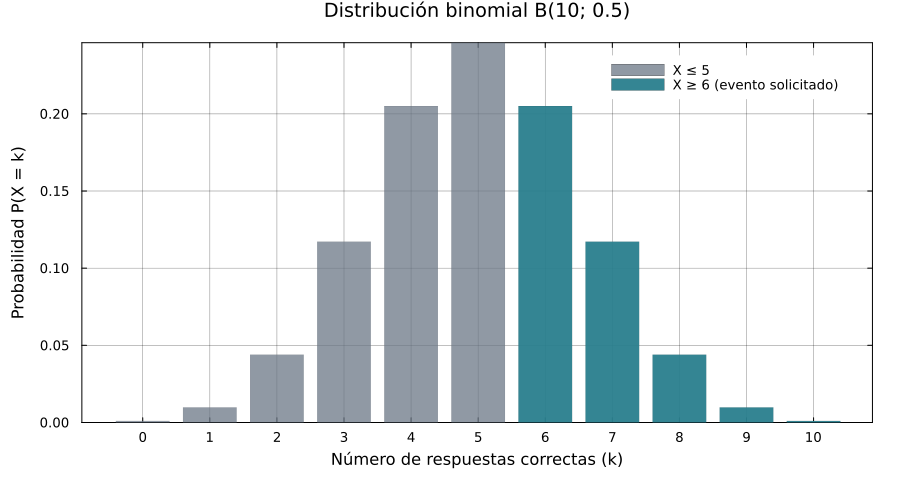

In [73]:
modelo_examen = Binomial(10, 0.5)
probabilidad_cola_superior = ccdf(modelo_examen, 5)
probabilidad_por_suma = sum(pdf(modelo_examen, aciertos) for aciertos in 6:10)

mostrar_tabla(["Método", "P(X ≥ 6)"], [
    ["Cola superior con ccdf(modelo, 5)", cifra(probabilidad_cola_superior)],
    ["Suma de las masas para k = 6, …, 10", cifra(probabilidad_por_suma)],
    ["Fracción exacta 193/512", cifra(193 / 512)],
])

aciertos_posibles = 0:10
masas_probabilidad = pdf.(modelo_examen, aciertos_posibles)

figura_examen = bar(aciertos_posibles[1:6], masas_probabilidad[1:6];
    color = PALETA.neutro,
    alpha = 0.75,
    linewidth = 0,
    label = "X ≤ 5",
    xlabel = "Número de respuestas correctas (k)",
    ylabel = "Probabilidad P(X = k)",
    title = "Distribución binomial B(10; 0.5)",
    xticks = aciertos_posibles)

bar!(figura_examen, aciertos_posibles[7:11], masas_probabilidad[7:11];
    color = PALETA.secundario,
    alpha = 0.95,
    linewidth = 0,
    label = "X ≥ 6 (evento solicitado)")

figura_examen


<span style="display:block; text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 1.</strong> Función de masa de probabilidad del número de respuestas correctas en el examen. Las barras verdes suman la probabilidad solicitada.</span>

#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultado.</strong> La probabilidad solicitada es:</span>

$$
P(X\geq 6)=\frac{193}{512}\approx 0.376953
$$

Adivinando, la probabilidad de aprobar con seis o más aciertos es cercana al 37.7 %. Es menor que $\frac{1}{2}$ porque el caso central $X=5$, que concentra el 24.6 % de la probabilidad, queda fuera del evento y se reparte por simetría entre ambas colas.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>

<div style="background:#1F3A5F; color:#FFFFFF; padding:11px 22px; margin:34px 0 6px 0; border-radius:4px; letter-spacing:0.08em; text-transform:uppercase; font-size:0.92em; font-weight:600;">Bloque II · Distribución normal</div>

<a id="ej-4-72"></a>

## Ejercicio 4.72 — Puntuaciones estándar y calificaciones

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** En un examen de estadística la media fue 78 y la desviación estándar fue 10. **(a)** Hallar las puntuaciones estándar de dos estudiantes cuyas calificaciones fueron 93 y 62. **(b)** Hallar las calificaciones correspondientes a las puntuaciones estándar $-0.6$ y $1.2$.

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Media | $\mu=78$ |
| Desviación estándar | $\sigma=10$ |
| Calificaciones del inciso (a) | $x=93,\ 62$ |
| Puntuaciones del inciso (b) | $z=-0.6,\ 1.2$ |

La puntuación estándar mide a cuántas desviaciones estándar se encuentra un valor respecto de la media:

$$
z=\frac{x-\mu}{\sigma}\qquad\Longleftrightarrow\qquad x=\mu+z\sigma.
$$

#### Desarrollo matemático

**(a) Puntuaciones estándar.**

$$
z_1=\frac{93-78}{10}=1.5,\qquad z_2=\frac{62-78}{10}=-1.6.
$$

**(b) Calificaciones.**

$$
x_1=78+(-0.6)(10)=72,\qquad x_2=78+(1.2)(10)=90.
$$

#### Implementación computacional

Se aplican las dos fórmulas de forma vectorizada: la primera sobre las calificaciones del inciso (a) y la segunda sobre las puntuaciones del inciso (b).

In [74]:
media_calificaciones = 78.0
desviacion_calificaciones = 10.0

calificaciones_conocidas = [93.0, 62.0]
puntuaciones_obtenidas = (calificaciones_conocidas .- media_calificaciones) ./ desviacion_calificaciones

puntuaciones_conocidas = [-0.6, 1.2]
calificaciones_obtenidas = media_calificaciones .+ puntuaciones_conocidas .* desviacion_calificaciones

filas_puntuaciones = [
    ["(a) Puntuación estándar", "x = " * cifra(x, "%.0f"), "z = " * cifra(z, "%.1f")]
    for (x, z) in zip(calificaciones_conocidas, puntuaciones_obtenidas)
]
filas_calificaciones = [
    ["(b) Calificación", "z = " * cifra(z, "%.1f"), "x = " * cifra(x, "%.0f")]
    for (z, x) in zip(puntuaciones_conocidas, calificaciones_obtenidas)
]

mostrar_tabla(["Inciso", "Dato", "Resultado"], vcat(filas_puntuaciones, filas_calificaciones))

Inciso,Dato,Resultado
(a) Puntuación estándar,x = 93,z = 1.5
(a) Puntuación estándar,x = 62,z = -1.6
(b) Calificación,z = -0.6,x = 72
(b) Calificación,z = 1.2,x = 90


#### Resultados e interpretación
<div style="border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Resultados.** **(a)** $z=1.5$ y $z=-1.6$. **(b)** $x=72$ y $x=90$.

</div>
El estudiante con 93 puntos se ubica una desviación y media por encima del promedio; el de 62, una desviación y seis décimas por debajo. Las calificaciones 72 y 90 quedan, respectivamente, a 0.6 desviaciones por debajo y a 1.2 por encima de la media.

<p style="text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></p>

<a id="ej-4-73"></a>

## Ejercicio 4.73 — Media y desviación estándar a partir de puntuaciones estándar

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Hallar **(a)** la media y **(b)** la desviación estándar de un examen en el que las calificaciones 70 y 88 corresponden, respectivamente, a las puntuaciones estándar $-0.6$ y $1.4$.

</div>

#### Datos y conceptos

| Calificación $x$ | Puntuación estándar $z$ |
|:--:|:--:|
| 70 | $-0.6$ |
| 88 | $1.4$ |

Cada pareja $(x,z)$ cumple $x=\mu+z\sigma$, de modo que los dos datos forman un sistema lineal en las incógnitas $\mu$ y $\sigma$.

#### Desarrollo matemático

**Paso 1. Sistema de ecuaciones.**

$$
\begin{cases}
70=\mu-0.6\,\sigma\\[2pt]
88=\mu+1.4\,\sigma
\end{cases}
$$

**Paso 2. Desviación estándar.** Al restar la primera ecuación de la segunda:

$$
18=2\sigma\quad\Longrightarrow\quad\sigma=9.
$$

**Paso 3. Media.** Sustituyendo en la primera ecuación:

$$
\mu=70+0.6(9)=75.4.
$$

**Comprobación.** $75.4+1.4(9)=88$, valor que coincide con el dato de la segunda ecuación.

#### Implementación computacional

Las fórmulas generales para dos parejas $(x_1,z_1)$ y $(x_2,z_2)$ son
$\sigma=\dfrac{x_2-x_1}{z_2-z_1}$ y $\mu=x_1-z_1\sigma$. La última fila de la tabla verifica que, con los parámetros hallados, se recuperan las puntuaciones originales.

In [75]:
calificaciones_dadas = [70.0, 88.0]
puntuaciones_dadas = [-0.6, 1.4]

desviacion_estimada = (calificaciones_dadas[2] - calificaciones_dadas[1]) /
                      (puntuaciones_dadas[2] - puntuaciones_dadas[1])
media_estimada = calificaciones_dadas[1] - puntuaciones_dadas[1] * desviacion_estimada

puntuaciones_recuperadas = (calificaciones_dadas .- media_estimada) ./ desviacion_estimada

mostrar_tabla(["Parámetro", "Valor"], [
    ["(a) Media μ", cifra(media_estimada, "%.1f")],
    ["(b) Desviación estándar σ", cifra(desviacion_estimada, "%.1f")],
    ["Puntuaciones recuperadas coinciden con los datos", ifelse(all(isapprox.(puntuaciones_recuperadas, puntuaciones_dadas)), "Sí", "No")],
])

Parámetro,Valor
(a) Media μ,75.4
(b) Desviación estándar σ,9.0
Puntuaciones recuperadas coinciden con los datos,Sí



#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong></span>

**(a)** $\mu=75.4$. **(b)** $\sigma=9$.

Las calificaciones 70 y 88 distan 18 puntos y esa distancia equivale a $1.4-(-0.6)=2$ desviaciones estándar, de donde se obtiene directamente $\sigma=9$.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="ej-4-75"></a>

## Ejercicio 4.75 — Áreas bajo la curva normal estándar

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Hallar las áreas bajo la curva normal estándar **(a)** a la izquierda de $z=-1.78$; **(b)** a la izquierda de $z=0.56$; **(c)** a la derecha de $z=-1.45$; **(d)** a la derecha de $z=2.16$; **(e)** entre $z=-0.80$ y $z=1.53$; **(f)** a la izquierda de $z=-2.52$ y a la derecha de $z=1.83$.

</div>

#### Datos y conceptos

Sea $Z\sim N(0,1)$ y $\Phi(z)=P(Z\leq z)$. Las áreas pedidas se obtienen con tres propiedades:

- **Complemento:** $P(Z>z)=1-\Phi(z)$.
- **Diferencia de áreas:** $P(a\leq Z\leq b)=\Phi(b)-\Phi(a)$.
- **Regiones disjuntas:** las áreas de dos colas separadas se suman.

#### Desarrollo matemático

| Inciso | Región | Expresión con $\Phi$ |
|:--:|:--|:--|
| (a) | $Z\leq -1.78$ | $\Phi(-1.78)$ |
| (b) | $Z\leq 0.56$ | $\Phi(0.56)$ |
| (c) | $Z>-1.45$ | $1-\Phi(-1.45)$ |
| (d) | $Z>2.16$ | $1-\Phi(2.16)$ |
| (e) | $-0.80\leq Z\leq 1.53$ | $\Phi(1.53)-\Phi(-0.80)$ |
| (f) | $Z\leq -2.52$ o $Z\geq 1.83$ | $\Phi(-2.52)+1-\Phi(1.83)$ |

En el inciso (f) las dos colas no se traslapan, por lo que sus áreas se suman.

#### Implementación computacional

Con `cdf` se obtiene el área a la izquierda y con `ccdf` el área a la derecha. La primera celda calcula y tabula las seis áreas; la segunda dibuja cada región con la función `grafica_region_normal`, que sombrea por separado cada tramo continuo.

In [76]:
normal_estandar = Normal()

regiones_areas = [
    ("(a)", "P(Z ≤ -1.78)", cdf(normal_estandar, -1.78)),
    ("(b)", "P(Z ≤ 0.56)", cdf(normal_estandar, 0.56)),
    ("(c)", "P(Z > -1.45)", ccdf(normal_estandar, -1.45)),
    ("(d)", "P(Z > 2.16)", ccdf(normal_estandar, 2.16)),
    ("(e)", "P(-0.80 ≤ Z ≤ 1.53)", cdf(normal_estandar, 1.53) - cdf(normal_estandar, -0.80)),
    ("(f)", "P(Z ≤ -2.52) + P(Z ≥ 1.83)", cdf(normal_estandar, -2.52) + ccdf(normal_estandar, 1.83)),
]

mostrar_tabla(["Inciso", "Región", "Área"], [
    [inciso, region, cifra(area, "%.4f")] for (inciso, region, area) in regiones_areas
])

Inciso,Región,Área
(a),P(Z ≤ -1.78),0.0375
(b),P(Z ≤ 0.56),0.7123
(c),P(Z > -1.45),0.9265
(d),P(Z > 2.16),0.0154
(e),P(-0.80 ≤ Z ≤ 1.53),0.7251
(f),P(Z ≤ -2.52) + P(Z ≥ 1.83),0.0395


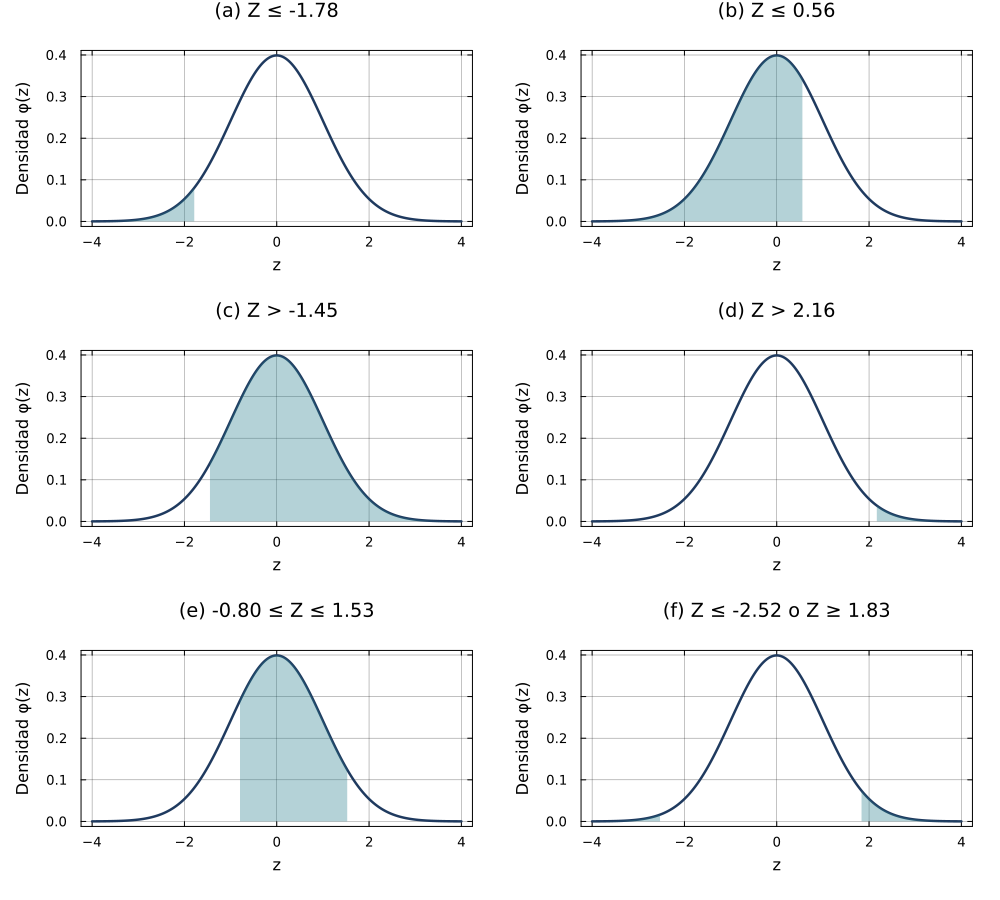

In [77]:
paneles_areas = [
    grafica_region_normal(normal_estandar, z -> z <= -1.78; titulo = "(a) Z ≤ -1.78", etiqueta_y = "Densidad φ(z)", leyenda = false),
    grafica_region_normal(normal_estandar, z -> z <= 0.56; titulo = "(b) Z ≤ 0.56", etiqueta_y = "Densidad φ(z)", leyenda = false),
    grafica_region_normal(normal_estandar, z -> z > -1.45; titulo = "(c) Z > -1.45", etiqueta_y = "Densidad φ(z)", leyenda = false),
    grafica_region_normal(normal_estandar, z -> z > 2.16; titulo = "(d) Z > 2.16", etiqueta_y = "Densidad φ(z)", leyenda = false),
    grafica_region_normal(normal_estandar, z -> -0.80 <= z <= 1.53; titulo = "(e) -0.80 ≤ Z ≤ 1.53", etiqueta_y = "Densidad φ(z)", leyenda = false),
    grafica_region_normal(normal_estandar, z -> z <= -2.52 || z >= 1.83; titulo = "(f) Z ≤ -2.52 o Z ≥ 1.83", etiqueta_y = "Densidad φ(z)", leyenda = false),
]

figura_areas = plot(paneles_areas...; layout = (3, 2), size = (1000, 900))
figura_areas


<span style="display:block; text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 2.</strong> Regiones bajo la curva normal estándar para los incisos (a) a (f). El área sombreada en verde azulado es la probabilidad solicitada.</span>

#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong> <strong>(a)</strong> 0.0375 &nbsp;·&nbsp; <strong>(b)</strong> 0.7123 &nbsp;·&nbsp; <strong>(c)</strong> 0.9265 &nbsp;·&nbsp; <strong>(d)</strong> 0.0154 &nbsp;·&nbsp; <strong>(e)</strong> 0.7251 &nbsp;·&nbsp; <strong>(f)</strong> 0.0395</span>

Por la simetría de la curva, el área del inciso (c) es $\Phi(1.45)$ y la del inciso (d) es $\Phi(-2.16)$. En el inciso (f) las dos colas extremas reúnen apenas el 3.95 % de la probabilidad total.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="ej-4-79"></a>

## Ejercicio 4.79 — Probabilidad de una variable normal

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Si $X$ tiene distribución normal con media 5 y desviación estándar 2, hallar $P(X>8)$.

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Distribución | $X\sim N(5,\,2^2)$ |
| Evento | $X>8$ |

Para calcular la probabilidad se estandariza el valor 8 y se usa el complemento de $\Phi$.

#### Desarrollo matemático

**Paso 1. Estandarización.**

$$
z=\frac{8-5}{2}=1.5.
$$

**Paso 2. Probabilidad.**

$$
P(X>8)=P(Z>1.5)=1-\Phi(1.5)\approx 0.0668.
$$

#### Implementación computacional

Se define directamente `Normal(5, 2)` y se evalúa `ccdf` en 8, sin estandarizar. La tabla incluye la puntuación $z$ para contrastar con el desarrollo analítico, y la figura sombrea la región en la escala original de la variable.

Magnitud,Valor
Puntuación estándar z,1.50
P(X > 8),0.0668
Porcentaje,6.68 %


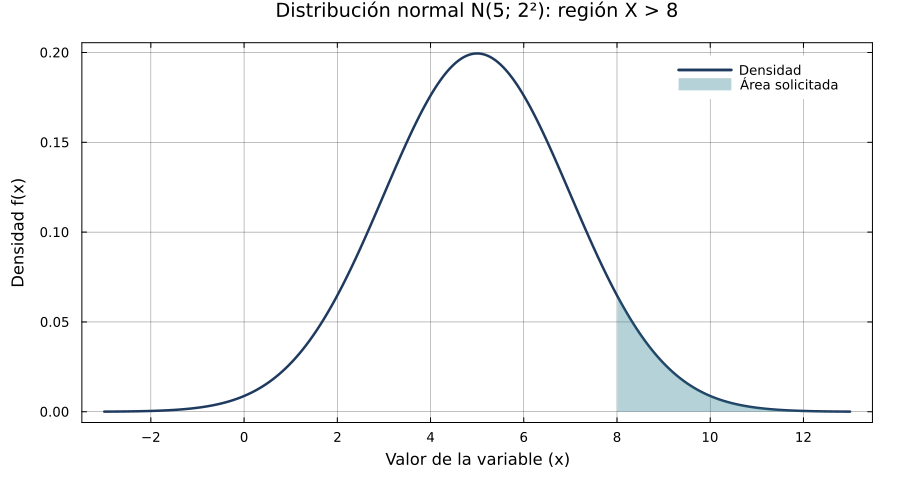

In [78]:
modelo_puntuaciones = Normal(5, 2)
puntuacion_limite = (8 - mean(modelo_puntuaciones)) / std(modelo_puntuaciones)
probabilidad_mayor_ocho = ccdf(modelo_puntuaciones, 8)

mostrar_tabla(["Magnitud", "Valor"], [
    ["Puntuación estándar z", cifra(puntuacion_limite, "%.2f")],
    ["P(X > 8)", cifra(probabilidad_mayor_ocho, "%.4f")],
    ["Porcentaje", cifra(100 * probabilidad_mayor_ocho, "%.2f") * " %"],
])

figura_mayor_ocho = grafica_region_normal(modelo_puntuaciones, x -> x > 8;
    titulo = "Distribución normal N(5; 2²): región X > 8",
    etiqueta_x = "Valor de la variable (x)",
    etiqueta_y = "Densidad f(x)")

figura_mayor_ocho

<p style="text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 3.</strong> Densidad de N(5; 2²) y región X > 8, ubicada a 1.5 desviaciones estándar por encima de la media.</p>

#### Resultados e interpretación
<div style="border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Resultado.** $$P(X>8)=1-\Phi(1.5)\approx 0.0668\quad(6.68\ \%)$$

</div>
Un valor superior a 8 se encuentra a más de una desviación y media sobre la media, por lo que solo ocurre en una de cada quince observaciones aproximadamente.

<p style="text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></p>

<a id="ej-4-83"></a>

## Ejercicio 4.83 — Distancias respecto a la media en una distribución normal

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Si un conjunto de mediciones tiene distribución normal, ¿qué porcentaje difiere de la media **(a)** en más de la mitad de la desviación estándar y **(b)** en menos de tres cuartas partes de la desviación estándar?

</div>

#### Datos y conceptos

Al estandarizar, la distancia de una medición a la media, medida en desviaciones estándar, es $\lvert Z\rvert$ con $Z\sim N(0,1)$. Por la simetría de la curva:

$$
P(\lvert Z\rvert>c)=2\,[1-\Phi(c)],\qquad P(\lvert Z\rvert<c)=2\,\Phi(c)-1.
$$

#### Desarrollo matemático

**(a) Más de media desviación estándar** ($c=0.5$):

$$
P(\lvert Z\rvert>0.5)=2\,[1-\Phi(0.5)]\approx 0.6171.
$$

**(b) Menos de tres cuartas partes de la desviación estándar** ($c=0.75$):

$$
P(\lvert Z\rvert<0.75)=2\,\Phi(0.75)-1\approx 0.5467.
$$

#### Implementación computacional

Se reutiliza la distribución `normal_estandar` del ejercicio 4.75. El inciso (a) emplea `ccdf` y el inciso (b) la diferencia de acumuladas, que no requiere recordar la identidad con $\Phi$.

In [79]:
probabilidad_mas_media_sigma = 2 * ccdf(normal_estandar, 0.5)
probabilidad_menos_tres_cuartos = cdf(normal_estandar, 0.75) - cdf(normal_estandar, -0.75)

mostrar_tabla(["Inciso", "Evento", "Probabilidad", "Porcentaje"], [
    ["(a)", "|Z| > 0.5", cifra(probabilidad_mas_media_sigma, "%.4f"), cifra(100 * probabilidad_mas_media_sigma, "%.2f") * " %"],
    ["(b)", "|Z| < 0.75", cifra(probabilidad_menos_tres_cuartos, "%.4f"), cifra(100 * probabilidad_menos_tres_cuartos, "%.2f") * " %"],
])

Inciso,Evento,Probabilidad,Porcentaje
(a),|Z| > 0.5,0.6171,61.71 %
(b),|Z| < 0.75,0.5467,54.67 %



#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong> <strong>(a)</strong> 61.71 % &nbsp;·&nbsp; <strong>(b)</strong> 54.67 %</span>

Más de la mitad de las mediciones se aleja de la media por más de $0.5\sigma$: la probabilidad complementaria de quedar dentro de ese margen es solo 38.29 %. Aun con un margen de $0.75\sigma$, apenas algo más de la mitad de los datos queda comprendido.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="ej-4-84"></a>

## Ejercicio 4.84 — Porcentajes en intervalos de una distribución normal

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Si $\mu$ es la media y $\sigma$ la desviación estándar de mediciones normalmente distribuidas, hallar el porcentaje de mediciones **(a)** dentro del intervalo $\mu\pm 2\sigma$; **(b)** fuera del intervalo $\mu\pm 1.2\sigma$; **(c)** mayores que $\mu-1.5\sigma$.

</div>

#### Datos y conceptos

Al estandarizar, cada intervalo expresado en términos de $\mu$ y $\sigma$ se convierte en un intervalo para $Z\sim N(0,1)$, y los resultados no dependen de los valores particulares de $\mu$ y $\sigma$.

#### Desarrollo matemático

**(a) Dentro de $\mu\pm 2\sigma$:**

$$
P(\mu-2\sigma\leq X\leq\mu+2\sigma)=P(-2\leq Z\leq 2)=\Phi(2)-\Phi(-2)\approx 0.9545.
$$

**(b) Fuera de $\mu\pm 1.2\sigma$:**

$$
P(\lvert Z\rvert>1.2)=2\,[1-\Phi(1.2)]\approx 0.2301.
$$

**(c) Mayores que $\mu-1.5\sigma$:**

$$
P(X>\mu-1.5\sigma)=P(Z>-1.5)=1-\Phi(-1.5)\approx 0.9332.
$$

#### Implementación computacional

Cada inciso se traduce en una sola expresión con `cdf` o `ccdf` sobre la distribución `normal_estandar`.

In [80]:
probabilidad_dentro_dos_sigma = cdf(normal_estandar, 2) - cdf(normal_estandar, -2)
probabilidad_fuera_uno_coma_dos = 2 * ccdf(normal_estandar, 1.2)
probabilidad_sobre_menos_uno_coma_cinco = ccdf(normal_estandar, -1.5)

mostrar_tabla(["Inciso", "Evento", "Probabilidad", "Porcentaje"], [
    ["(a)", "μ − 2σ ≤ X ≤ μ + 2σ", cifra(probabilidad_dentro_dos_sigma, "%.4f"), cifra(100 * probabilidad_dentro_dos_sigma, "%.2f") * " %"],
    ["(b)", "|X − μ| > 1.2σ", cifra(probabilidad_fuera_uno_coma_dos, "%.4f"), cifra(100 * probabilidad_fuera_uno_coma_dos, "%.2f") * " %"],
    ["(c)", "X > μ − 1.5σ", cifra(probabilidad_sobre_menos_uno_coma_cinco, "%.4f"), cifra(100 * probabilidad_sobre_menos_uno_coma_cinco, "%.2f") * " %"],
])

Inciso,Evento,Probabilidad,Porcentaje
(a),μ − 2σ ≤ X ≤ μ + 2σ,0.9545,95.45 %
(b),|X − μ| > 1.2σ,0.2301,23.01 %
(c),X > μ − 1.5σ,0.9332,93.32 %



#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong> <strong>(a)</strong> 95.45 % &nbsp;·&nbsp; <strong>(b)</strong> 23.01 % &nbsp;·&nbsp; <strong>(c)</strong> 93.32 %</span>

El inciso (a) corresponde a la regla empírica de los dos sigmas: cerca del 95 % de las mediciones queda dentro de $\mu\pm 2\sigma$. Las respuestas del libro, basadas en tablas impresas, pueden diferir en la última cifra por redondeo.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<div style="background:#1F3A5F; color:#FFFFFF; padding:11px 22px; margin:34px 0 6px 0; border-radius:4px; letter-spacing:0.08em; text-transform:uppercase; font-size:0.92em; font-weight:600;">Bloque III · Aproximaciones y distribución de Poisson</div>

<a id="ej-4-88"></a>

## Ejercicio 4.88 — Aproximación normal a la distribución binomial

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Una máquina produce pernos de los cuales el 10 % son defectuosos. En una muestra aleatoria de 400 pernos, hallar la probabilidad de que el número de defectuosos sea **(a)** como máximo 30; **(b)** entre 30 y 50; **(c)** entre 35 y 45; **(d)** 65 o más.

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Tamaño de la muestra | $n=400$ |
| Probabilidad de defecto | $p=0.10,\quad q=0.90$ |
| Media de la binomial | $\mu=np=40$ |
| Desviación estándar | $\sigma=\sqrt{npq}=6$ |

El número de defectuosos es $X\sim\mathrm{Bin}(400,\,0.10)$. Como $np=40$ y $nq=360$ son grandes, se aproxima $X$ con $Y\sim N(40,\,6^2)$. Dado que $X$ es discreta y $Y$ continua, se aplica la **corrección de continuidad**: cada límite entero se desplaza media unidad hacia afuera del evento.

#### Desarrollo matemático

**(a) Como máximo 30:**

$$
P(X\leq 30)\approx P(Y\leq 30.5)=\Phi\!\left(\frac{30.5-40}{6}\right)=\Phi(-1.583)\approx 0.0567.
$$

**(b) Entre 30 y 50, ambos incluidos:**

$$
P(30\leq X\leq 50)\approx P(29.5\leq Y\leq 50.5)=\Phi(1.75)-\Phi(-1.75)\approx 0.9199.
$$

**(c) Entre 35 y 45, ambos incluidos:**

$$
P(35\leq X\leq 45)\approx P(34.5\leq Y\leq 45.5)=\Phi(0.917)-\Phi(-0.917)\approx 0.6407.
$$

**(d) 65 o más:**

$$
P(X\geq 65)\approx P(Y\geq 64.5)=1-\Phi\!\left(\frac{64.5-40}{6}\right)=1-\Phi(4.083)\approx 2.22\times 10^{-5}.
$$
<div style="border:1px solid rgba(192,138,43,0.50); border-left:5px solid #C08A2B; background:rgba(192,138,43,0.09); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Observación sobre la clave del libro.** El enunciado impreso dice «65 o más», pero la respuesta publicada para el inciso (d) es 0.0079. Ese valor no corresponde a $X\geq 65$ con $\mu=40$ y $\sigma=6$; coincide aproximadamente con el evento $X\geq 55$. Se conserva y resuelve el enunciado impreso, sin modificar el dato para ajustarlo a la clave. La celda de código incluye la comparación con $X\geq 55$ para documentar la diferencia.

</div>

#### Implementación computacional

La celda construye la binomial exacta y su aproximación normal, y evalúa cada inciso con los límites corregidos por continuidad. La primera tabla contrasta la aproximación con la probabilidad binomial exacta; la segunda documenta la discrepancia del inciso (d). La figura superpone la función de masa binomial y la densidad normal.

In [81]:
numero_pernos = 400
proporcion_defectuosos = 0.10
media_defectuosos = numero_pernos * proporcion_defectuosos
desviacion_defectuosos = sqrt(numero_pernos * proporcion_defectuosos * (1 - proporcion_defectuosos))

modelo_binomial_pernos = Binomial(numero_pernos, proporcion_defectuosos)
aproximacion_normal_pernos = Normal(media_defectuosos, desviacion_defectuosos)

aproximaciones_normales = [
    cdf(aproximacion_normal_pernos, 30.5),
    cdf(aproximacion_normal_pernos, 50.5) - cdf(aproximacion_normal_pernos, 29.5),
    cdf(aproximacion_normal_pernos, 45.5) - cdf(aproximacion_normal_pernos, 34.5),
    ccdf(aproximacion_normal_pernos, 64.5),
]

probabilidades_exactas = [
    cdf(modelo_binomial_pernos, 30),
    cdf(modelo_binomial_pernos, 50) - cdf(modelo_binomial_pernos, 29),
    cdf(modelo_binomial_pernos, 45) - cdf(modelo_binomial_pernos, 34),
    ccdf(modelo_binomial_pernos, 64),
]

incisos_pernos = ["(a)", "(b)", "(c)", "(d)"]
eventos_pernos = ["P(X ≤ 30)", "P(30 ≤ X ≤ 50)", "P(35 ≤ X ≤ 45)", "P(X ≥ 65)"]

mostrar_tabla(["Inciso", "Evento", "Aproximación normal", "Binomial exacta"], [
    [inciso, evento, cifra(aproximada, "%.7f"), cifra(exacta, "%.7f")]
    for (inciso, evento, aproximada, exacta) in zip(incisos_pernos, eventos_pernos, aproximaciones_normales, probabilidades_exactas)
])

probabilidad_cincuenta_y_cinco_o_mas = ccdf(aproximacion_normal_pernos, 54.5)

mostrar_tabla(["Evento comparado", "Aproximación normal", "Valor publicado en la clave"], [
    ["P(X ≥ 55)", cifra(probabilidad_cincuenta_y_cinco_o_mas, "%.7f"), "0.0079"],
    ["P(X ≥ 65), enunciado impreso", cifra(aproximaciones_normales[4], "%.7f"), "No aplica"],
])

Inciso,Evento,Aproximación normal,Binomial exacta
(a),P(X ≤ 30),0.0566728,0.0523912
(b),P(30 ≤ X ≤ 50),0.9198817,0.9206950
(c),P(35 ≤ X ≤ 45),0.6406827,0.6409201
(d),P(X ≥ 65),0.0000222,0.0000704


Evento comparado,Aproximación normal,Valor publicado en la clave
P(X ≥ 55),0.0078317,0.0079
"P(X ≥ 65), enunciado impreso",0.0000222,No aplica


La figura siguiente se genera en una celda aparte para mantener separados el cálculo y la visualización.

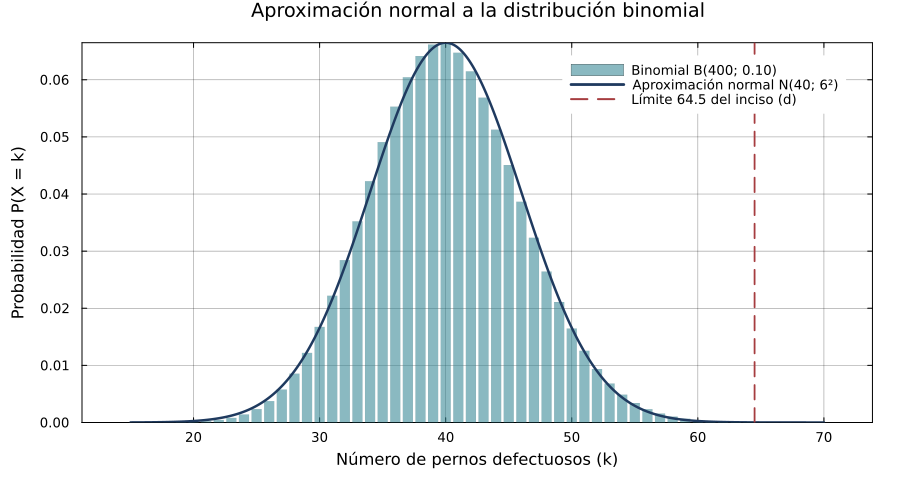

In [82]:
defectuosos_graficados = 15:70
masas_binomiales = pdf.(modelo_binomial_pernos, defectuosos_graficados)
valores_continuos = range(15, 70; length = 400)

figura_pernos = bar(defectuosos_graficados, masas_binomiales;
    color = PALETA.secundario,
    alpha = 0.55,
    linewidth = 0,
    label = "Binomial B(400; 0.10)",
    xlabel = "Número de pernos defectuosos (k)",
    ylabel = "Probabilidad P(X = k)",
    title = "Aproximación normal a la distribución binomial")

plot!(figura_pernos, valores_continuos, pdf.(aproximacion_normal_pernos, valores_continuos);
    color = PALETA.primario,
    label = "Aproximación normal N(40; 6²)")

vline!(figura_pernos, [64.5];
    color = PALETA.alerta,
    linestyle = :dash,
    linewidth = 1.8,
    label = "Límite 64.5 del inciso (d)")

figura_pernos


<span style="display:block; text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 4.</strong> Función de masa binomial B(400; 0.10) y su aproximación normal N(40; 6²). La línea discontinua marca el límite 64.5 del inciso (d), en la cola derecha extrema.</span>

#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados con corrección de continuidad.</strong> <strong>(a)</strong> 0.0567 &nbsp;·&nbsp; <strong>(b)</strong> 0.9199 &nbsp;·&nbsp; <strong>(c)</strong> 0.6407 &nbsp;·&nbsp; <strong>(d)</strong> 2.22 × 10⁻⁵</span>

En la zona central los incisos (a), (b) y (c) difieren de la binomial exacta en menos de 0.005, lo que confirma la calidad de la aproximación. En la cola extrema del inciso (d) la binomial exacta, cercana a $7.04\times 10^{-5}$, es unas tres veces mayor que la estimación normal: la aproximación debe usarse con cautela lejos de la media.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="ej-4-90"></a>

## Ejercicio 4.90 — Distribución de Poisson

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Si el 3 % de las bombillas fabricadas por una compañía son defectuosas, hallar la probabilidad de que en una muestra de 100 bombillas sean defectuosas **(a)** 0; **(b)** 1; **(c)** 2; **(d)** 3; **(e)** 4; **(f)** 5 bombillas.

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Tamaño de la muestra | $n=100$ |
| Probabilidad de defecto | $p=0.03$ |
| Parámetro de Poisson | $\lambda=np=3$ |

Con $n$ grande y $p$ pequeño, la binomial se aproxima por una distribución de Poisson con $\lambda=np$. Si $X\sim\mathrm{Poisson}(3)$:

$$
P(X=k)=\frac{e^{-3}\,3^{k}}{k!},\qquad P(X=k+1)=\frac{\lambda}{k+1}\,P(X=k).
$$

#### Desarrollo matemático

Se parte de $P(X=0)=e^{-3}$ y se aplica la relación recursiva:

$$
\begin{aligned}
P(X=0)&=e^{-3}\approx 0.04979,\\
P(X=1)&=3\,P(X=0)\approx 0.14936,\\
P(X=2)&=\tfrac{3}{2}\,P(X=1)\approx 0.22404,\\
P(X=3)&=\tfrac{3}{3}\,P(X=2)\approx 0.22404,\\
P(X=4)&=\tfrac{3}{4}\,P(X=3)\approx 0.16803,\\
P(X=5)&=\tfrac{3}{5}\,P(X=4)\approx 0.10082.
\end{aligned}
$$

#### Implementación computacional

La celda evalúa la función de masa de `Poisson(λ)` para $k=0,\dots,5$ y añade, como contraste, la probabilidad de la binomial exacta `Binomial(100, 0.03)`. La figura muestra la masa de Poisson para $k=0,\dots,10$ con los valores binomiales superpuestos.

Inciso,k,Aproximación de Poisson,Binomial exacta
(a),0,0.04979,0.04755
(b),1,0.14936,0.14707
(c),2,0.22404,0.22515
(d),3,0.22404,0.22747
(e),4,0.16803,0.17061
(f),5,0.10082,0.10131


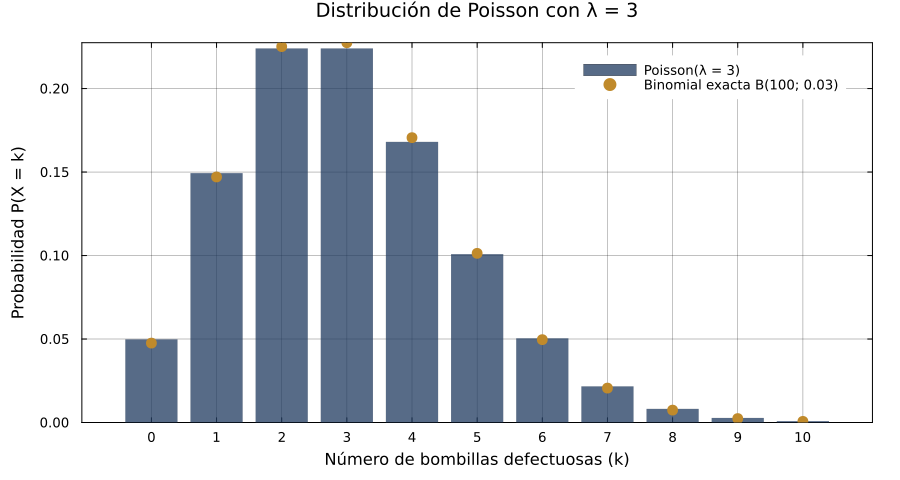

In [83]:
parametro_poisson = 100 * 0.03
modelo_poisson = Poisson(parametro_poisson)
modelo_binomial_bombillas = Binomial(100, 0.03)

incisos_bombillas = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]
defectuosas_solicitadas = 0:5

mostrar_tabla(["Inciso", "k", "Aproximación de Poisson", "Binomial exacta"], [
    [inciso, string(k), cifra(pdf(modelo_poisson, k), "%.5f"), cifra(pdf(modelo_binomial_bombillas, k), "%.5f")]
    for (inciso, k) in zip(incisos_bombillas, defectuosas_solicitadas)
])

soporte_poisson = 0:10

figura_poisson = bar(soporte_poisson, pdf.(modelo_poisson, soporte_poisson);
    color = PALETA.primario,
    alpha = 0.75,
    linewidth = 0,
    label = "Poisson(λ = 3)",
    xlabel = "Número de bombillas defectuosas (k)",
    ylabel = "Probabilidad P(X = k)",
    title = "Distribución de Poisson con λ = 3",
    xticks = soporte_poisson)

scatter!(figura_poisson, soporte_poisson, pdf.(modelo_binomial_bombillas, soporte_poisson);
    color = PALETA.acento,
    markersize = 6,
    markerstrokewidth = 0,
    label = "Binomial exacta B(100; 0.03)")

figura_poisson


<span style="display:block; text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 5.</strong> Función de masa de Poisson con λ = 3 (barras) y probabilidades binomiales exactas (puntos ocres).</span>

#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong> <strong>(a)</strong> 0.04979 &nbsp;·&nbsp; <strong>(b)</strong> 0.14936 &nbsp;·&nbsp; <strong>(c)</strong> 0.22404 &nbsp;·&nbsp; <strong>(d)</strong> 0.22404 &nbsp;·&nbsp; <strong>(e)</strong> 0.16803 &nbsp;·&nbsp; <strong>(f)</strong> 0.10082</span>

Como $\lambda=3$ es entero, las probabilidades de $k=2$ y $k=3$ son iguales y constituyen la moda doble de la distribución. La aproximación de Poisson difiere de la binomial exacta en menos de 0.004 para todos los valores de $k$ considerados.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<div style="background:#1F3A5F; color:#FFFFFF; padding:11px 22px; margin:34px 0 6px 0; border-radius:4px; letter-spacing:0.08em; text-transform:uppercase; font-size:0.92em; font-weight:600;">Bloque IV · Distribución hipergeométrica</div>

<a id="ej-4-99"></a>

## Ejercicio 4.99 — Distribución hipergeométrica

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Se seleccionan al azar, sin reemplazo, 13 cartas de una baraja ordinaria de 52. Hallar la probabilidad de que **(a)** 6 sean cartas con figura (*picture cards*) y **(b)** ninguna sea carta con figura.

</div>

#### Datos y conceptos

La selección sin reemplazo de una población finita con dos tipos de elementos sigue una distribución hipergeométrica:

$$
P(X=k)=\frac{\binom{K}{k}\binom{N-K}{n-k}}{\binom{N}{n}}.
$$

Para concordar con la clave de respuestas del texto base, se adopta su parametrización:

| Magnitud | Valor |
|:--|:--:|
| Tamaño de la población | $N=52$ |
| Elementos con la característica | $K=13$ |
| Elementos restantes | $N-K=39$ |
| Tamaño de la muestra | $n=13$ |

#### Desarrollo matemático

**(a) Exactamente 6 cartas con figura:**

$$
P(X=6)=\frac{\binom{13}{6}\binom{39}{7}}{\binom{52}{13}}\approx 0.041564.
$$

**(b) Ninguna carta con figura:**

$$
P(X=0)=\frac{\binom{13}{0}\binom{39}{13}}{\binom{52}{13}}\approx 0.012791.
$$
<div style="border:1px solid rgba(192,138,43,0.50); border-left:5px solid #C08A2B; background:rgba(192,138,43,0.09); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Observación sobre la parametrización.** Una baraja ordinaria contiene 12 cartas con figura (J, Q y K de cuatro palos), mientras que la clave del libro utiliza 13 en las combinaciones. Se conserva la parametrización del solucionario para seguir el texto base y no se sustituye silenciosamente el dato. Como contraste meramente informativo, la tabla de la celda siguiente incluye también los valores con $K=12$.

</div>

#### Implementación computacional

En Julia, `Hypergeometric(s, f, n)` recibe el número de elementos con la característica, el número de elementos restantes y el tamaño de la muestra. La tabla presenta los resultados de la parametrización del solucionario y, aparte, la convención de 12 cartas con figura.

In [84]:
modelo_cartas_solucionario = Hypergeometric(13, 39, 13)
modelo_cartas_doce_figuras = Hypergeometric(12, 40, 13)

mostrar_tabla(["Inciso", "Evento", "Solucionario (K = 13)", "Contraste informativo (K = 12)"], [
    ["(a)", "P(X = 6)", cifra(pdf(modelo_cartas_solucionario, 6)), cifra(pdf(modelo_cartas_doce_figuras, 6))],
    ["(b)", "P(X = 0)", cifra(pdf(modelo_cartas_solucionario, 0)), cifra(pdf(modelo_cartas_doce_figuras, 0))],
])

Inciso,Evento,Solucionario (K = 13),Contraste informativo (K = 12)
(a),P(X = 6),0.041564,0.027128
(b),P(X = 0),0.012791,0.018950



#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados según la parametrización del solucionario.</strong> <strong>(a)</strong> 0.041564 &nbsp;·&nbsp; <strong>(b)</strong> 0.012791</span>

Con $K=13$ el valor esperado de cartas con característica en la muestra es $13\cdot\frac{13}{52}=3.25$, por lo que obtener 6 es poco probable y obtener 0 lo es aún más. La columna de contraste muestra que el cambio de $K$ altera las probabilidades de forma apreciable, razón por la cual la elección se documenta.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="ej-4-100"></a>

## Ejercicio 4.100 — Distribución hipergeométrica

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** De 60 aspirantes a una universidad, 40 proceden del Este. Se seleccionan 20 aspirantes al azar. Hallar la probabilidad de que **(a)** exactamente 10 y **(b)** no más de 2 procedan del Este.

</div>

#### Datos y conceptos

| Magnitud | Valor |
|:--|:--:|
| Aspirantes | $N=60$ |
| Aspirantes del Este | $K=40$ |
| Aspirantes de otras regiones | $N-K=20$ |
| Seleccionados | $n=20$ |

Sea $X$ el número de seleccionados que proceden del Este. Como la selección es sin reemplazo, $X$ es hipergeométrica:

$$
P(X=k)=\frac{\binom{40}{k}\binom{20}{20-k}}{\binom{60}{20}}.
$$

#### Desarrollo matemático

**(a) Exactamente 10 del Este:**

$$
P(X=10)=\frac{\binom{40}{10}\binom{20}{10}}{\binom{60}{20}}\approx 0.037361.
$$

**(b) No más de 2 del Este:**

$$
P(X\leq 2)=\frac{\binom{40}{0}\binom{20}{20}+\binom{40}{1}\binom{20}{19}+\binom{40}{2}\binom{20}{18}}{\binom{60}{20}}\approx 3.5545\times 10^{-11}.
$$

#### Implementación computacional

Se emplean `pdf` para el inciso (a) y `cdf` para el inciso (b), con una comprobación explícita mediante la suma de los casos $k=0,1,2$. La figura usa escala logarítmica en el eje vertical, necesaria para apreciar probabilidades que difieren en muchos órdenes de magnitud.

Inciso,Evento,Probabilidad
(a),P(X = 10),0.037361
(b),P(X ≤ 2) con cdf,3.5545e-11
(b),"P(X ≤ 2) por suma de k = 0, 1, 2",3.5545e-11


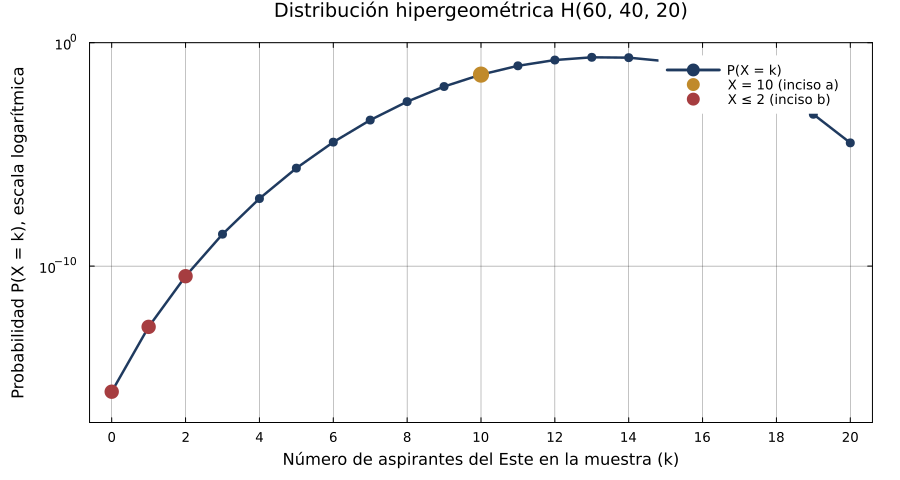

In [85]:
modelo_aspirantes = Hypergeometric(40, 20, 20)
probabilidad_exactamente_diez = pdf(modelo_aspirantes, 10)
probabilidad_a_lo_sumo_dos = cdf(modelo_aspirantes, 2)
probabilidad_suma_casos = sum(pdf(modelo_aspirantes, k) for k in 0:2)

mostrar_tabla(["Inciso", "Evento", "Probabilidad"], [
    ["(a)", "P(X = 10)", cifra(probabilidad_exactamente_diez, "%.6f")],
    ["(b)", "P(X ≤ 2) con cdf", cifra(probabilidad_a_lo_sumo_dos, "%.4e")],
    ["(b)", "P(X ≤ 2) por suma de k = 0, 1, 2", cifra(probabilidad_suma_casos, "%.4e")],
])

soporte_aspirantes = 0:20
masas_aspirantes = pdf.(modelo_aspirantes, soporte_aspirantes)

figura_aspirantes = plot(soporte_aspirantes, masas_aspirantes;
    color = PALETA.primario,
    marker = :circle,
    markersize = 5,
    markerstrokewidth = 0,
    yscale = :log10,
    ylims = (1e-17, 1),
    label = "P(X = k)",
    xlabel = "Número de aspirantes del Este en la muestra (k)",
    ylabel = "Probabilidad P(X = k), escala logarítmica",
    title = "Distribución hipergeométrica H(60, 40, 20)",
    xticks = 0:2:20)

scatter!(figura_aspirantes, [10], [probabilidad_exactamente_diez];
    color = PALETA.acento,
    markersize = 9,
    markerstrokewidth = 0,
    label = "X = 10 (inciso a)")

scatter!(figura_aspirantes, 0:2, masas_aspirantes[1:3];
    color = PALETA.alerta,
    markersize = 8,
    markerstrokewidth = 0,
    label = "X ≤ 2 (inciso b)")

figura_aspirantes


<span style="display:block; text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 6.</strong> Función de masa hipergeométrica en escala logarítmica. Los puntos rojos ($X\leq 2$) tienen probabilidades del orden de $10^{-16}$ a $10^{-11}$.</span>

#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong></span>

**(a)** $P(X=10)\approx 0.037361$ &nbsp;·&nbsp; **(b)** $P(X\leq 2)\approx 3.5545\times 10^{-11}$

Como dos tercios de los aspirantes proceden del Este, se esperan unos $20\cdot\frac{40}{60}\approx 13.3$ en la muestra; por eso observar 2 o menos es prácticamente imposible, mientras que exactamente 10 aún tiene una probabilidad del 3.7 %.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<div style="background:#1F3A5F; color:#FFFFFF; padding:11px 22px; margin:34px 0 6px 0; border-radius:4px; letter-spacing:0.08em; text-transform:uppercase; font-size:0.92em; font-weight:600;">Bloque V · Distribución uniforme</div>

<a id="ej-4-102"></a>

## Ejercicio 4.102 — Momentos centrales de la distribución uniforme

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Hallar **(a)** el tercer momento y **(b)** el cuarto momento respecto a la media de una distribución uniforme.

</div>

#### Datos y conceptos

Sea $X\sim U(a,b)$, con densidad y media

$$
f(x)=\frac{1}{b-a},\quad a\leq x\leq b,\qquad \mu=\frac{a+b}{2}.
$$

El momento central de orden $r$ es

$$
\mu_r=E\bigl[(X-\mu)^r\bigr]=\frac{1}{b-a}\int_a^b (x-\mu)^r\,dx.
$$

Con el cambio $u=x-\mu$, los límites de integración pasan a ser $\mp\dfrac{b-a}{2}$.

#### Desarrollo matemático

**(a) Tercer momento central.** El integrando $u^3$ es impar y el intervalo es simétrico:

$$
\mu_3=\frac{1}{b-a}\int_{-(b-a)/2}^{(b-a)/2}u^3\,du=0.
$$

**(b) Cuarto momento central.**

$$
\begin{aligned}
\mu_4&=\frac{1}{b-a}\int_{-(b-a)/2}^{(b-a)/2}u^4\,du
=\frac{1}{b-a}\left[\frac{u^5}{5}\right]_{-(b-a)/2}^{(b-a)/2}\\[4pt]
&=\frac{1}{b-a}\cdot\frac{2}{5}\left(\frac{b-a}{2}\right)^{5}=\frac{(b-a)^4}{80}.
\end{aligned}
$$

#### Implementación computacional

Se verifican las fórmulas en tres intervalos de ejemplo. Los momentos se calculan de dos formas independientes: mediante las antiderivadas $u^4/4$ y $u^5/5$ evaluadas en los límites, y mediante la curtosis que entrega `Distributions.jl`, usando la relación $\mu_4=(\kappa+3)\,\sigma^4$, donde $\kappa$ es la curtosis en exceso.

In [86]:
intervalos_uniformes = [(2.0, 8.0), (0.0, 1.0), (-3.0, 5.0)]

filas_momentos = map(intervalos_uniformes) do (limite_inferior, limite_superior)
    media_uniforme = (limite_inferior + limite_superior) / 2
    amplitud = limite_superior - limite_inferior
    tercer_momento = ((limite_superior - media_uniforme)^4 - (limite_inferior - media_uniforme)^4) / (4 * amplitud)
    cuarto_momento = ((limite_superior - media_uniforme)^5 - (limite_inferior - media_uniforme)^5) / (5 * amplitud)
    modelo_uniforme = Uniform(limite_inferior, limite_superior)
    cuarto_momento_paquete = (kurtosis(modelo_uniforme) + 3) * var(modelo_uniforme)^2
    [
        "[" * cifra(limite_inferior, "%.1f") * ", " * cifra(limite_superior, "%.1f") * "]",
        cifra(tercer_momento),
        cifra(cuarto_momento),
        cifra(amplitud^4 / 80),
        cifra(cuarto_momento_paquete),
    ]
end

mostrar_tabla(["Intervalo [a, b]", "μ₃ (integral)", "μ₄ (integral)", "(b − a)⁴ / 80", "μ₄ (Distributions.jl)"], filas_momentos)

"Intervalo [a, b]",μ₃ (integral),μ₄ (integral),(b − a)⁴ / 80,μ₄ (Distributions.jl)
"[2.0, 8.0]",0.000000,16.200000,16.200000,16.200000
"[0.0, 1.0]",0.000000,0.012500,0.012500,0.012500
"[-3.0, 5.0]",0.000000,51.200000,51.200000,51.200000



#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong></span>

**(a)** $\mu_3=0$ &nbsp;·&nbsp; **(b)** $\mu_4=\dfrac{(b-a)^4}{80}$

El tercer momento nulo expresa la simetría de la distribución. Como $\sigma^2=\dfrac{(b-a)^2}{12}$, el cuarto momento equivale a $\mu_4=\dfrac{9}{5}\sigma^4$: la uniforme tiene una curtosis de 1.8, menor que la de la normal (3), es decir, es más achatada y carece de colas.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<div style="background:#1F3A5F; color:#FFFFFF; padding:11px 22px; margin:34px 0 6px 0; border-radius:4px; letter-spacing:0.08em; text-transform:uppercase; font-size:0.92em; font-weight:600;">Bloque VI · Distribución t de Student</div>

<a id="ej-4-116"></a>

## Ejercicio 4.116 — Cuantiles de la distribución t de Student

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Para una distribución t de Student con 15 grados de libertad, hallar $t_1$ tal que **(a)** el área a la derecha sea 0.01; **(b)** el área a la izquierda sea 0.95; **(c)** el área a la derecha sea 0.10; **(d)** la suma de las áreas a la derecha de $t_1$ y a la izquierda de $-t_1$ sea 0.01; **(e)** el área entre $-t_1$ y $t_1$ sea 0.95.

</div>

#### Datos y conceptos

Sea $T\sim t_{15}$. La función `quantile` de Julia entrega el valor cuya probabilidad acumulada a la izquierda es el argumento dado. Como la distribución t es simétrica, las áreas de dos colas se reparten por igual.

#### Desarrollo matemático

| Inciso | Condición | Acumulado a la izquierda | Valor buscado |
|:--:|:--|:--:|:--:|
| (a) | Área derecha $=0.01$ | $0.99$ | $t_{0.99,\,15}$ |
| (b) | Área izquierda $=0.95$ | $0.95$ | $t_{0.95,\,15}$ |
| (c) | Área derecha $=0.10$ | $0.90$ | $t_{0.90,\,15}$ |
| (d) | Dos colas suman $0.01$ (cada una $0.005$) | $0.995$ | $t_{0.995,\,15}$ |
| (e) | Área central $=0.95$ (cada cola $0.025$) | $0.975$ | $t_{0.975,\,15}$ |

#### Implementación computacional

La celda aplica `quantile` sobre `TDist(15)` a las cinco probabilidades acumuladas de la tabla anterior.

In [87]:
modelo_t_quince = TDist(15)

condiciones_t = [
    ("(a)", "Área derecha = 0.01", 0.99),
    ("(b)", "Área izquierda = 0.95", 0.95),
    ("(c)", "Área derecha = 0.10", 0.90),
    ("(d)", "Suma de las dos colas = 0.01", 0.995),
    ("(e)", "Área central = 0.95", 0.975),
]

mostrar_tabla(["Inciso", "Condición", "Acumulado a la izquierda", "t₁"], [
    [inciso, condicion, cifra(acumulado, "%.3f"), cifra(quantile(modelo_t_quince, acumulado), "%.4f")]
    for (inciso, condicion, acumulado) in condiciones_t
])

Inciso,Condición,Acumulado a la izquierda,t₁
(a),Área derecha = 0.01,0.990,2.6025
(b),Área izquierda = 0.95,0.950,1.7531
(c),Área derecha = 0.10,0.900,1.3406
(d),Suma de las dos colas = 0.01,0.995,2.9467
(e),Área central = 0.95,0.975,2.1314



#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong> <strong>(a)</strong> 2.60 &nbsp;·&nbsp; <strong>(b)</strong> 1.75 &nbsp;·&nbsp; <strong>(c)</strong> 1.34 &nbsp;·&nbsp; <strong>(d)</strong> 2.95 &nbsp;·&nbsp; <strong>(e)</strong> 2.13</span>

Para el área central de 0.95, el valor $t_1=2.13$ supera al valor normal 1.96: con pocos grados de libertad la distribución t tiene colas más pesadas y exige intervalos más amplios.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="ej-4-117"></a>

## Ejercicio 4.117 — Valores críticos de la distribución t de Student

<hr style="border:0; border-top:3px solid #2A7F8E; width:72px; margin:2px 0 16px 0;">

<div style="border:1px solid rgba(31,58,95,0.30); border-left:5px solid #1F3A5F; background:rgba(31,58,95,0.06); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Enunciado.** Hallar los valores de $t$ para los cuales el área de la cola derecha de la distribución t es 0.01, cuando los grados de libertad son **(a)** 4, **(b)** 12, **(c)** 25, **(d)** 60 y **(e)** 150.

</div>

#### Datos y conceptos

Para cada número de grados de libertad $\nu$ se busca $t$ tal que $P(T_\nu>t)=0.01$. Por complemento, $P(T_\nu\leq t)=0.99$, de modo que el valor buscado es el percentil 99:

$$
t=t_{0.99,\,\nu}=\operatorname{quantile}(t_\nu,\ 0.99).
$$

Cuando $\nu\to\infty$, la distribución t converge a la normal estándar, cuyo percentil 99 es $z_{0.99}\approx 2.3263$.

#### Desarrollo matemático

El procedimiento es el mismo para los cinco valores de $\nu$: se plantea $P(T_\nu\leq t)=0.99$ y se despeja $t$ con la función cuantil de $t_\nu$. No existe una expresión cerrada sencilla, por lo que el valor se obtiene numéricamente.

#### Implementación computacional

La tabla reúne los cinco valores críticos y su diferencia respecto del límite normal. La figura traza el valor crítico como función de $\nu$ en escala logarítmica, con los cinco valores solicitados resaltados.

Inciso,Grados de libertad ν,t₀.₉₉(ν),Diferencia con z₀.₉₉
(a),4,3.7469,1.4206
(b),12,2.6810,0.3547
(c),25,2.4851,0.1588
(d),60,2.3901,0.0638
(e),150,2.3515,0.0251


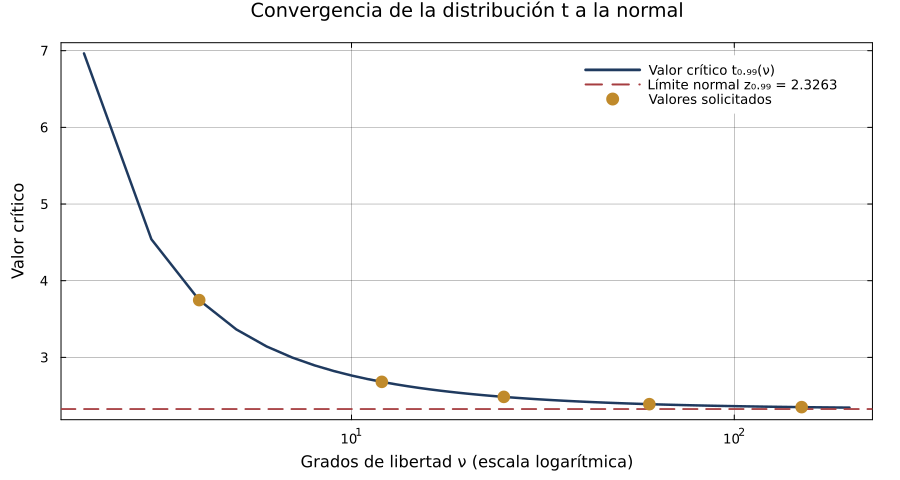

In [88]:
grados_libertad = [4, 12, 25, 60, 150]
valores_criticos = [quantile(TDist(nu), 0.99) for nu in grados_libertad]
limite_normal = quantile(normal_estandar, 0.99)

mostrar_tabla(["Inciso", "Grados de libertad ν", "t₀.₉₉(ν)", "Diferencia con z₀.₉₉"], [
    [inciso, string(nu), cifra(critico, "%.4f"), cifra(critico - limite_normal, "%.4f")]
    for (inciso, nu, critico) in zip(["(a)", "(b)", "(c)", "(d)", "(e)"], grados_libertad, valores_criticos)
])

grados_curva = 2:200
valores_curva = [quantile(TDist(nu), 0.99) for nu in grados_curva]

figura_criticos = plot(grados_curva, valores_curva;
    color = PALETA.primario,
    xscale = :log10,
    label = "Valor crítico t₀.₉₉(ν)",
    xlabel = "Grados de libertad ν (escala logarítmica)",
    ylabel = "Valor crítico",
    title = "Convergencia de la distribución t a la normal")

hline!(figura_criticos, [limite_normal];
    color = PALETA.alerta,
    linestyle = :dash,
    linewidth = 1.8,
    label = "Límite normal z₀.₉₉ = " * cifra(limite_normal, "%.4f"))

scatter!(figura_criticos, grados_libertad, valores_criticos;
    color = PALETA.acento,
    markersize = 7,
    markerstrokewidth = 0,
    label = "Valores solicitados")

figura_criticos


<span style="display:block; text-align:center; font-size:0.92em; color:#6B7785;"><strong>Figura 7.</strong> Valor crítico de cola derecha 0.01 en función de los grados de libertad. La curva decrece hacia el percentil 99 de la normal estándar (línea discontinua).</span>

#### Resultados e interpretación

<span style="display:block; border:1px solid rgba(42,127,142,0.40); border-left:5px solid #2A7F8E; background:rgba(42,127,142,0.09); padding:12px 20px; margin:14px 0; border-radius:4px;"><strong>Resultados.</strong> <strong>(a)</strong> 3.75 &nbsp;·&nbsp; <strong>(b)</strong> 2.68 &nbsp;·&nbsp; <strong>(c)</strong> 2.49 &nbsp;·&nbsp; <strong>(d)</strong> 2.39 &nbsp;·&nbsp; <strong>(e)</strong> 2.35</span>

Los valores críticos disminuyen al aumentar $\nu$ y, con 150 grados de libertad, ya están a menos de 0.03 del límite normal 2.3263. Con muestras pequeñas la exigencia es sensiblemente mayor, como muestra el valor 3.75 para $\nu=4$.

<span style="display:block; text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></span>


<a id="sec-resumen"></a>

# 5. Resumen de resultados

| Ejercicio | Resultados principales |
|:--|:--|
| [4.66](#ej-4-66) | $P(X=1)=64/243\approx 0.263374$ |
| [4.67](#ej-4-67) | $P(X\geq 6)=193/512\approx 0.376953$ |
| [4.72](#ej-4-72) | (a) $z=1.5$ y $z=-1.6$; (b) $x=72$ y $x=90$ |
| [4.73](#ej-4-73) | $\mu=75.4$; $\sigma=9$ |
| [4.75](#ej-4-75) | (a) 0.0375; (b) 0.7123; (c) 0.9265; (d) 0.0154; (e) 0.7251; (f) 0.0395 |
| [4.79](#ej-4-79) | $P(X>8)\approx 0.0668$ |
| [4.83](#ej-4-83) | (a) 61.71 %; (b) 54.67 % |
| [4.84](#ej-4-84) | (a) 95.45 %; (b) 23.01 %; (c) 93.32 % |
| [4.88](#ej-4-88) | (a) 0.0567; (b) 0.9199; (c) 0.6407; (d) $2.22\times 10^{-5}$ para «65 o más» |
| [4.90](#ej-4-90) | 0.04979; 0.14936; 0.22404; 0.22404; 0.16803; 0.10082 |
| [4.99](#ej-4-99) | (a) 0.041564; (b) 0.012791, con la parametrización 13/39 del solucionario |
| [4.100](#ej-4-100) | (a) 0.037361; (b) $3.5545\times 10^{-11}$ |
| [4.102](#ej-4-102) | (a) $\mu_3=0$; (b) $\mu_4=(b-a)^4/80$ |
| [4.116](#ej-4-116) | (a) 2.60; (b) 1.75; (c) 1.34; (d) 2.95; (e) 2.13 |
| [4.117](#ej-4-117) | (a) 3.75; (b) 2.68; (c) 2.49; (d) 2.39; (e) 2.35 |

<a id="sec-observaciones"></a>

# 6. Observaciones sobre la fuente
<div style="border:1px solid rgba(192,138,43,0.50); border-left:5px solid #C08A2B; background:rgba(192,138,43,0.09); padding:2px 20px; margin:14px 0; border-radius:4px;">

**Inconsistencias detectadas.** 1. **Ejercicio 4.88(d).** El enunciado impreso indica «65 o más», pero la clave de respuestas informa 0.0079. El cálculo con el enunciado impreso da una probabilidad mucho menor; la clave parece corresponder a «55 o más». Se mantuvo el dato del enunciado.
2. **Ejercicio 4.99.** La clave de respuestas emplea $\binom{13}{k}$ y $\binom{39}{13-k}$, mientras que una baraja ordinaria tiene 12 cartas con figura. Se reprodujo la parametrización del solucionario y se añadió el contraste con $K=12$ solo como información.
3. **Redondeo.** Las cifras se presentan redondeadas. Las diferencias en la última cifra respecto del libro pueden deberse al redondeo de las tablas impresas frente al cálculo numérico de Julia; por ejemplo, el inciso (a) del ejercicio 4.84 vale 0.9545 con precisión de cuatro decimales.

</div>

<a id="sec-referencias"></a>

# 7. Referencias bibliográficas

- Spiegel, M. R., Schiller, J. J., & Srinivasan, R. A. (2013). *Schaum's Outline of Probability and Statistics* (4.ª ed.). McGraw-Hill. Capítulo 4, problemas suplementarios, pp. 145-148; respuestas, pp. 149-150.
- JuliaStats. *Distributions.jl: Probability distributions and associated functions*. https://juliastats.org/Distributions.jl/stable/
- JuliaStats. *StatsBase.jl: Sampling from a population*. https://juliastats.org/StatsBase.jl/latest/sampling/
- Plots.jl. *Plots documentation*. https://docs.juliaplots.org/stable/

<p style="text-align:right; font-size:0.9em;"><a href="#sec-indice">Volver al índice</a></p>